In [23]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [33]:
def f(x):
    return 2*x**2 - 3*x + 4

In [8]:
f(3)

13

In [9]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
ys

array([69.   , 63.375, 58.   , 52.875, 48.   , 43.375, 39.   , 34.875,
       31.   , 27.375, 24.   , 20.875, 18.   , 15.375, 13.   , 10.875,
        9.   ,  7.375,  6.   ,  4.875,  4.   ,  3.375,  3.   ,  2.875,
        3.   ,  3.375,  4.   ,  4.875,  6.   ,  7.375,  9.   , 10.875,
       13.   , 15.375, 18.   , 20.875, 24.   , 27.375, 31.   , 34.875])

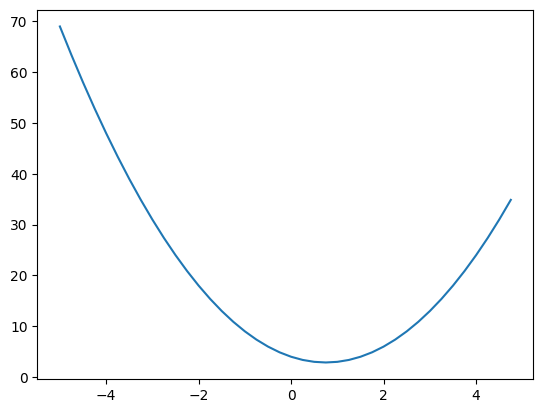

In [10]:
plt.plot(xs, ys)

In [13]:
h = 0.0000001
x = 3.0
(f(x+h) - f(x))/h


9.00000017622915

In [15]:
h = 0.0000001
x = -3.0
(f(x+h) - f(x))/h


-14.999999784492957

In [16]:
h = 0.0000001
x = 3/4
(f(x+h) - f(x))/h

1.9984014443252818e-07

In [17]:
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)


4.0


In [18]:
h = 0.0001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
a +=h
d2 = a*b + c

print(f"d1: {d1}, d2: {d2}")
print(f"slope: {(d2-d1)/h}")

def f(x):
    return 2*x**2 - 3*x + 4
f(3)


d1: 4.0, d2: 3.999699999999999
slope: -3.000000000010772


13

In [19]:
h = 0.0001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
b +=h
d2 = a*b + c

print(f"d1: {d1}, d2: {d2}")
print(f"slope: {(d2-d1)/h}")

def f(x):
    return 2*x**2 - 3*x + 4
f(3)


d1: 4.0, d2: 4.0002
slope: 2.0000000000042206


13

In [20]:
h = 0.0001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
c +=h
d2 = a*b + c

print(f"d1: {d1}, d2: {d2}")
print(f"slope: {(d2-d1)/h}")

def f(x):
    return 2*x**2 - 3*x + 4
f(3)


d1: 4.0, d2: 4.0001
slope: 0.9999999999976694


13

In [225]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._backward = lambda: None
        self._op = _op
        self.label = label
        self.grad = 0.0

    def __repr__(self):
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out
    
    def __radd__(self, other):
        return self + other

    def __sub__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data - other.data, (self, other), '-')
        def _backward():
            self.grad += out.grad
            other.grad += -out.grad
        out._backward = _backward
        return out
    
    def __rsub__(self, other):
        return self * -1 + other

    def __neg__(self):
        return self * -1
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward
        return out

    def __rmul__(self, other):
        return self * other

    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self.grad += out.grad * (1-t**2)
        out._backward = _backward
        return out
    
    def exp(self):
        x = self.data
        t = math.exp(x)
        out = Value(t, (self, ), 'exp')
        def _backward():
            self.grad += out.grad * t
        out._backward = _backward
        return out

    def __truediv__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return self * other**-1

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only int and float supported"
        out = Value(self.data**other, (self,), f'**{other}')
        def _backward():
            self.grad += out.grad * other * self.data**(other-1)
        out._backward = _backward
        return out

    def backward(self):

        self.grad = 1.0

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        for node in reversed(topo):
            node._backward()




In [104]:
a = Value(2.0, label='a')
a + 2

Value(data=4.0)

In [105]:
a * 2

Value(data=4.0)

In [106]:
2 * a

Value(data=4.0)

In [ ]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b
e.label = 'e'
d = e + c
d.label = 'd'
f = Value(-2.0, label='f')
l = d*f
l.label = 'l'
print(l)

In [14]:
print(a._prev, a._op, a.label)
print(b._prev, b._op, b.label)
print(c._prev, c._op, c.label)
print(e._prev, e._op, e.label)
print(d._prev, d._op, d.label)
print(f._prev, f._op, f.label)
print(l._prev, l._op, l.label)




set()  a
set()  b
set()  c
{Value(data=2.0), Value(data=-3.0)} * e
{Value(data=-6.0), Value(data=10.0)} + d
set()  f
{Value(data=4.0), Value(data=-2.0)} * l


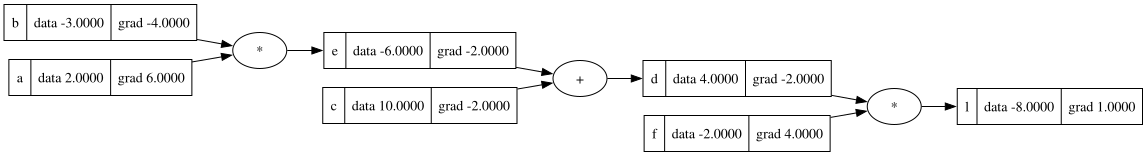

In [101]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

draw_dot(l)

Lgrad  = dL/dL =1

In [15]:
l.grad = 1.0

d.grad = dL/dd

f.grad = dL/df

L = d*f

dL/dd = f = -2 = d.grad

dL/df = d = 4 = f.grad

In [16]:
f.grad = 4
d.grad = -2

c.grad = dL/dc

e.grad = dL/de

d = c + e

dd/dc = 1 = dd/de

c.grad = dL/dc = dL/dd * dd/dc = -2*1 = -2

e.grad = dL/de = dL/dd * dd/dc = -2*1 = -2



In [17]:
c.grad = -2
e.grad = -2


a.grad = dL/da

b.grad = dL/db

e = a*b

de/db = a = 2

de/da = b = -3

a.grad = dL/da = dL/de * de/da = -2 * -3 = 6

b.grad = dL/db = dL/de * de/db = -2 * 2 = -4


In [18]:
a.grad = 6
b.grad = -4

[text](https://mriquestions.com/what-is-a-neural-network.html)

In [93]:
# inputs 
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.881373587019543, label='b')

# forward pass
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n' 
o = n.tanh(); o.label = 'o'


In [94]:
o.backward()

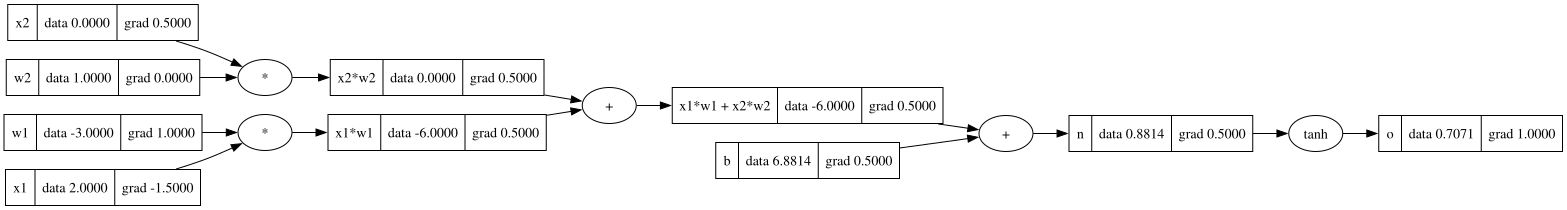

In [96]:
draw_dot(o)

In [75]:
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=2.0),
 Value(data=-3.0),
 Value(data=-6.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-6.0),
 Value(data=6.881373587019543),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [ ]:
o.grad = 1.0

topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

In [62]:
o.grad = 1.0

In [65]:
o._backward()
n._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()
x1._backward()
x2._backward()


n.grad = do/dn

o = tanh(n)

do/dn = 1- tanh(n)**2 = 1  - o^2

In [45]:
n.grad = 1 - o.data**2
n.grad

0.4999999999999999

x1w1x2w2.grad = do/dx1w1x2w2

db.grad = do/db

n = x1w1x2w2 + b

dn/dx1w1x2w2 = 1

dn/db = 1

x1w1x2w2.grad = do/dx1w1x2w2 = do/dn * dn/dx1w1x2w2 = n.grad * 1

b.grad = do/db =do/dn * dn/b = n.grad * 1

In [50]:
x1w1x2w2.grad = n.grad * 1
b.grad = n.grad * 1
print(x1w1x2w2.grad)
print(b.grad)


0.4999999999999999
0.4999999999999999


x1w1x2w2 = x1w1 + x2w2

dx1w1x2w2/dx1w1 = 1

dx1w1x2w2/dx2w2 = 1

x1w1.grad = do/dx1w1 = do/dx1w1x2w2 * dx1w1x2w2/dx1w1 = x1w1x2w2.grad * 1

x2w2.grad = do/dx2w2 = do/dx1w1x2w2 * dx1w1x2w2/dx2w2 = x1w1x2w2.grad * 1

In [52]:
x1w1.grad = x1w1x2w2.grad * 1

x2w2.grad = x1w1x2w2.grad * 1
print(x1w1.grad)
print(x2w2.grad)



0.4999999999999999
0.4999999999999999


x1.grad = do/dx1 = do/dx1w1 * dx1w1/dx1 

w1.grad = do/dw1 = do/dx1w1 * dx1w1/dw1 


x1w1 = x1 * w1

dx1w1/dx1 = w1

dx1w1/dw1 = x1

x1.grad = x1w1.grad * w1.data

w1.grad = x1w1.grad * x1.data

In [54]:
x1.grad = x1w1.grad * w1.data

w1.grad = x1w1.grad * x1.data

print(x1.grad)
print(w1.grad)


-1.4999999999999996
0.9999999999999998


x2.grad = do/dx2 = do/dx2w2 * dx2w2/dx2 
 
w2.grad = do/dw2 = do/dx2w2 * dx2w2/dw2 


x2w2 = x2 * w2

dx2w2/dx2 = w2

dx2w2/dw2 = x2

x2.grad = x2w2.grad * w2.data

w2.grad = x2w2.grad * x2.data

In [56]:
x2.grad = x2w2.grad * w2.data

w2.grad = x2w2.grad * x2.data

print(x2.grad)
print(w2.grad)


0.4999999999999999
0.0


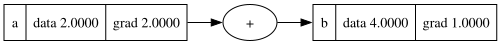

In [102]:
a = Value(2.0, label='a')
b = a+a; b.label = 'b'
b.backward()
draw_dot(b)

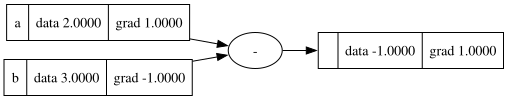

In [117]:
a = Value(2.0, label='a')
b = Value(3.0, label='b')
c = a - b
c.backward()
draw_dot(c)

In [123]:
# inputs 
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.881373587019543, label='b')

# forward pass
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n' 

# -----------
e = (2*n).exp()
o = (e-1)/(e+1); o.label = 'o'

In [124]:
o.backward()

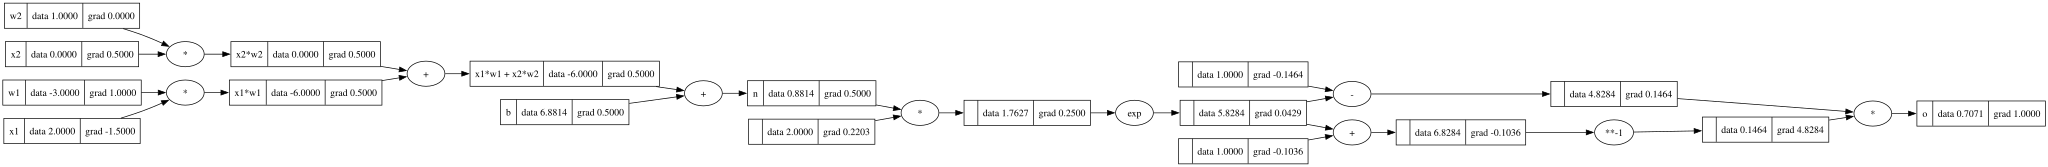

In [125]:
draw_dot(o)

In [144]:
import torch

x1 = torch.tensor(2.0).double() ; x1.requires_grad = True
x2 = torch.tensor(0.0).double() ; x2.requires_grad = True
w1 = torch.tensor(-3.0).double() ; w1.requires_grad = True
w2 = torch.tensor(1.0).double() ; w2.requires_grad = True
b = torch.tensor(6.881373587019543).double() ; b.requires_grad = True

n = x1*w1 + x2*w2 + b ; n.retain_grad()
o = torch.tanh(n) ; o.retain_grad()
o.backward()

In [145]:
print(f"x1.grad: {x1.grad}")
print(f"x2.grad: {x2.grad}")
print(f"w1.grad: {w1.grad}")
print(f"w2.grad: {w2.grad}")
print(f"b.grad: {b.grad}")
print(f"n.grad: {n.grad}")
print(f"o.grad: {o.grad}")


x1.grad: -1.5000003851533106
x2.grad: 0.5000001283844369
w1.grad: 1.0000002567688737
w2.grad: 0.0
b.grad: 0.5000001283844369
n.grad: 0.5000001283844369
o.grad: 1.0


In [138]:
o.grad

/var/folders/25/2l93dsz54sz5s03cln49j0fm0000gn/T/ipykernel_80428/3391283232.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:494.)
  o.grad


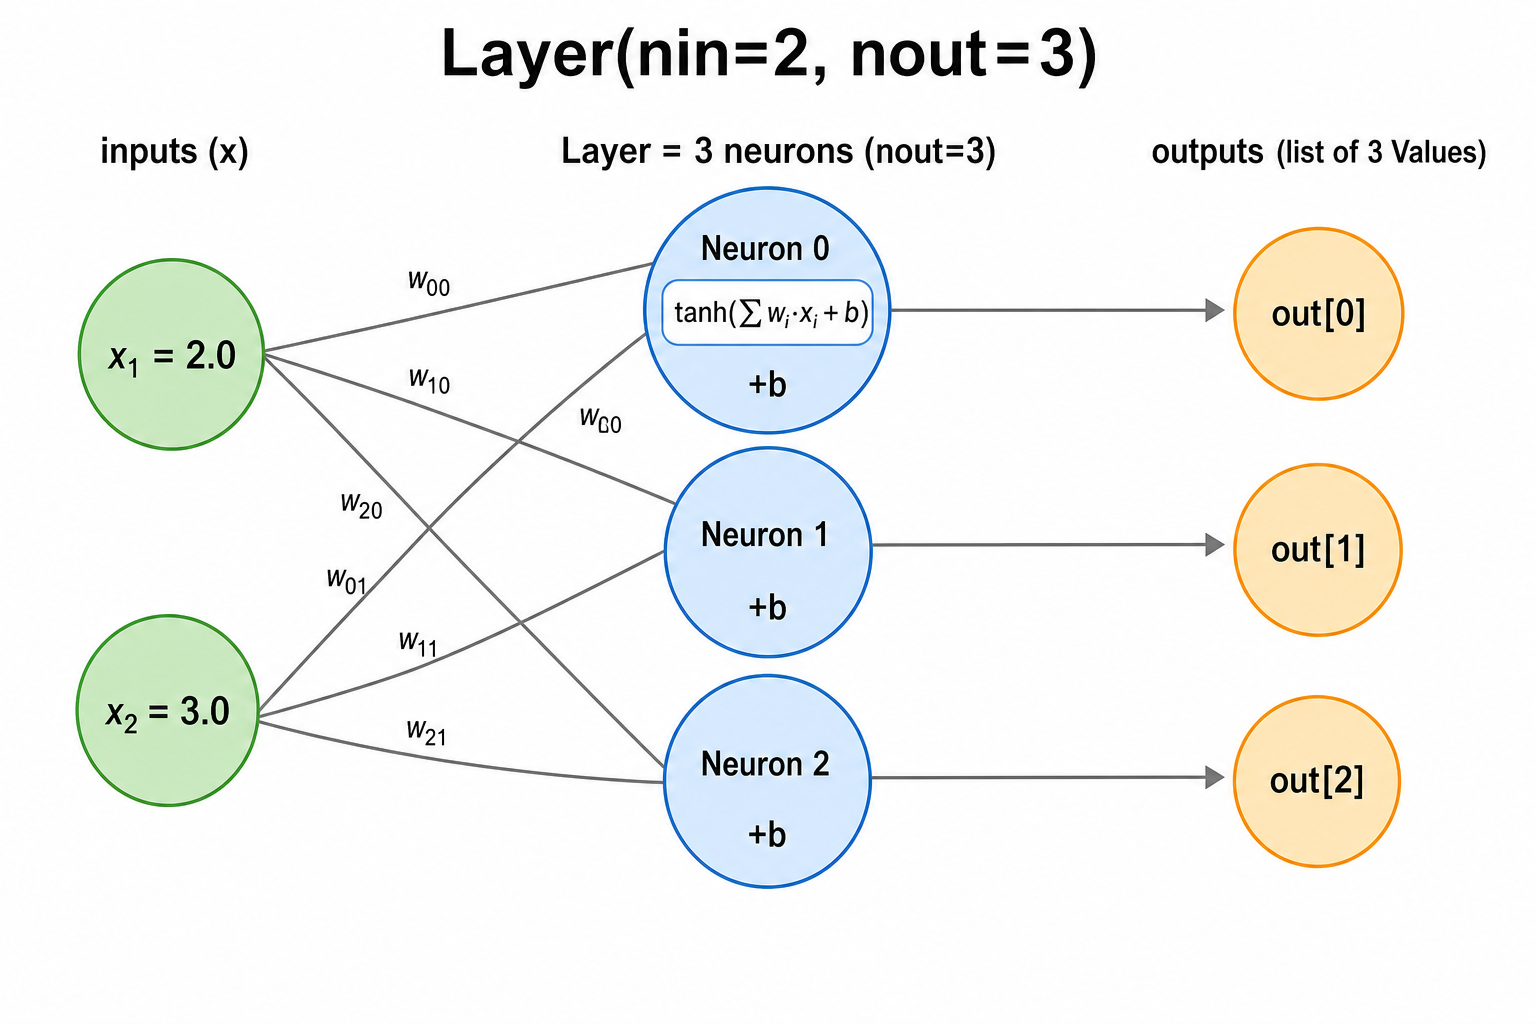

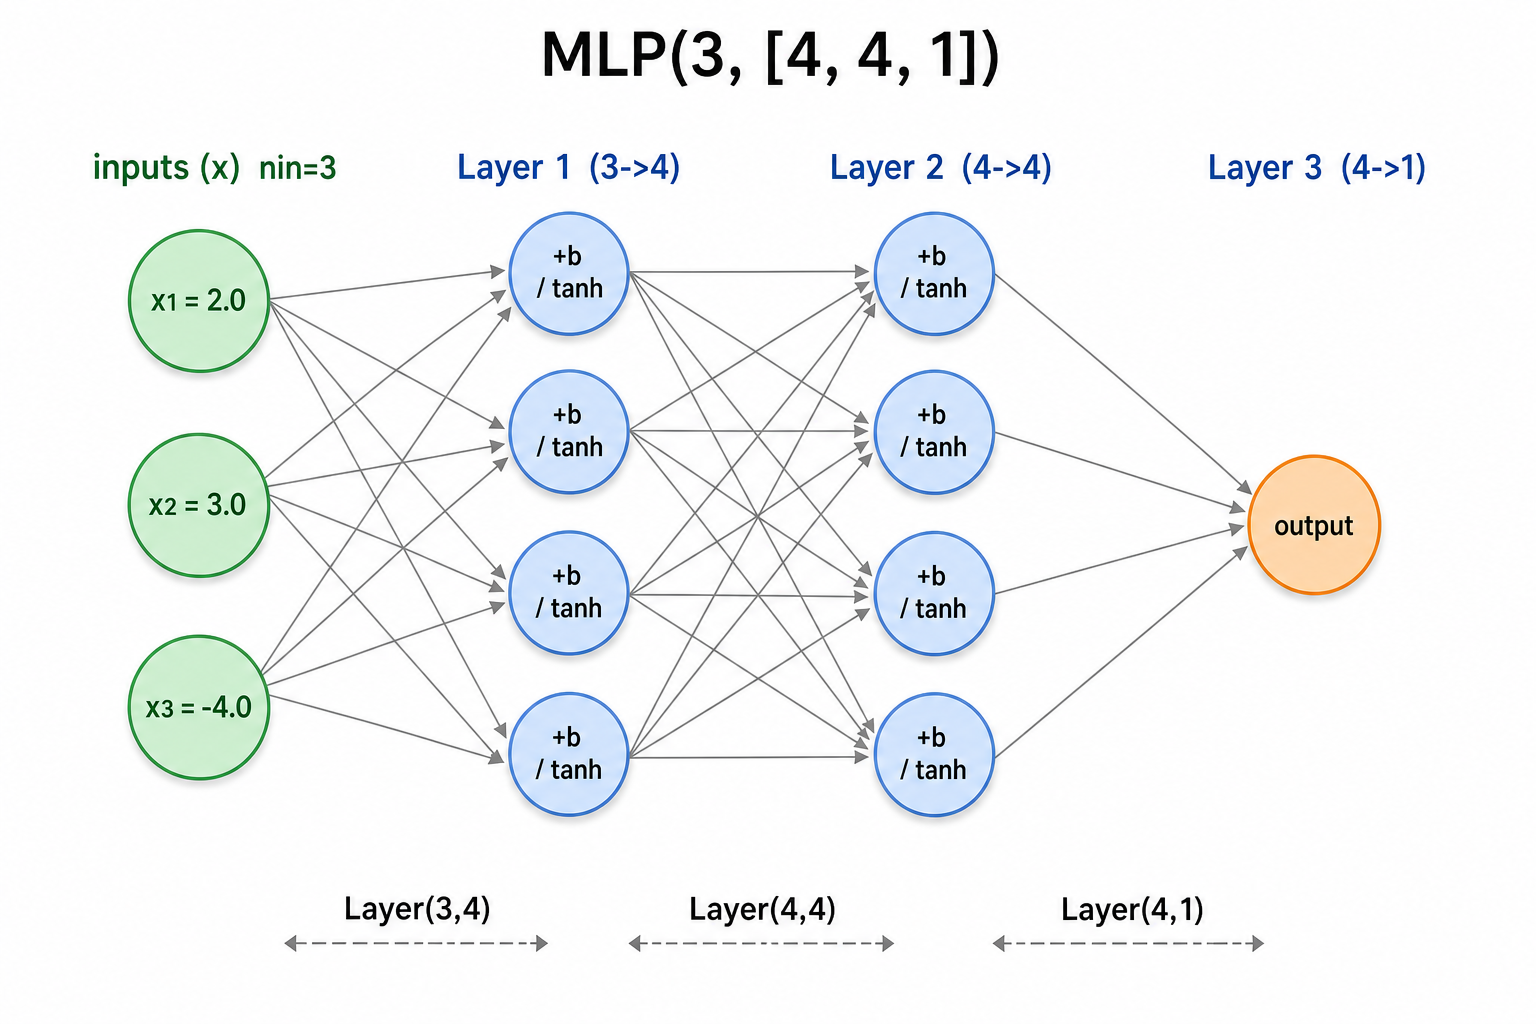

In [183]:
from IPython.display import Image, display

display(Image(filename='layers.png'))

display(Image(filename='mlp.png'))

In [309]:
from typing import Any


import random

class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        activation = self.b
        for w, x in zip(self.w, x):
            activation += w*x
        output = activation.tanh()
        return output

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

m = MLP(3, [4,4,1])

In [310]:
xs = [
    [Value(2.0), Value(3.0), Value(-1.0)],
    [Value(3.0), Value(-1.0), Value(0.5)],
    [Value(0.5), Value(1.0), Value(1.0)],
    [Value(1.0), Value(1.0), Value(-1.0)]
]
ys = [1.0, -1.0, -1.0, 1.0]


In [311]:
ypred = [m(x) for x in xs]
ypred

[Value(data=-0.21569072761483765),
 Value(data=-0.7366736462005125),
 Value(data=-0.6102448288113912),
 Value(data=0.7489111715387385)]

In [299]:
loss = sum((yout-ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=6.998982591100732)

In [276]:
loss.backward()

In [277]:
m.layers[0].neurons[0].w[0]

Value(data=0.5233328583695795)

In [278]:
m.layers[0].neurons[0].w[0].grad

1.3791463569081195

p.grad > 0 → increasing p increases loss → so to reduce loss, decrease p.

p.grad < 0 → increasing p decreases loss → so to reduce loss, increase p.

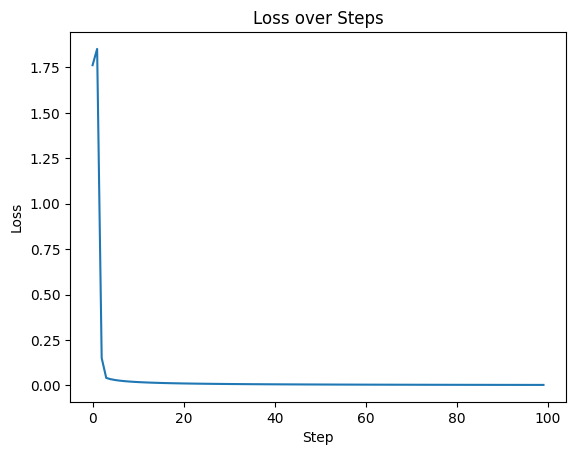

In [312]:
plot = []
for step in range(100):
    ypred = [m(x) for x in xs]
    loss = sum((yout-ygt)**2 for ygt, yout in zip(ys, ypred))
    for p in m.parameters():
        p.grad = 0
    loss.backward()
    for p in m.parameters():
        p.data += -0.1 * p.grad

    plot.append([step, loss.data])

import matplotlib.pyplot as plt
steps, losses = zip(*plot)
plt.plot(steps, losses)
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('Loss over Steps')
plt.show()


In [313]:
plot

[[0, 1.7621994070603368],
 [1, 1.8518032052239388],
 [2, 0.1503867427419801],
 [3, 0.040919578682363705],
 [4, 0.033789273740472185],
 [5, 0.02914610576343597],
 [6, 0.025791213694279117],
 [7, 0.023214604060173515],
 [8, 0.02115410235789316],
 [9, 0.019458118234334847],
 [10, 0.018031592432388558],
 [11, 0.016811250238730015],
 [12, 0.015753000443205725],
 [13, 0.014824984896013726],
 [14, 0.014003497278476607],
 [15, 0.013270462678492533],
 [16, 0.012611814987486068],
 [17, 0.012016415220574351],
 [18, 0.011475308708692681],
 [19, 0.010981201791209379],
 [20, 0.010528084854506042],
 [21, 0.010110955436754804],
 [22, 0.00972561129313006],
 [23, 0.00936849334842009],
 [24, 0.009036564856330165],
 [25, 0.008727217256248827],
 [26, 0.00843819599959698],
 [27, 0.008167541508706837],
 [28, 0.00791354173946015],
 [29, 0.007674693738782731],
 [30, 0.0074496722444457476],
 [31, 0.007237303849314836],
 [32, 0.007036545599800711],
 [33, 0.006846467155760764],
 [34, 0.006666235831892704],
 [35, 